## Dataset Mental Disorders



# PARTIE 1 — EXPLORATION & PRÉTRAITEMENT

## 1.1 Imports

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from imblearn.over_sampling import SMOTE
from tensorflow.keras.models     import Sequential
from tensorflow.keras.layers     import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils      import to_categorical
from tensorflow.keras.callbacks  import EarlyStopping, ReduceLROnPlateau
warnings.filterwarnings('ignore')
%matplotlib inline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing  import StandardScaler
from sklearn.ensemble        import RandomForestClassifier
from sklearn.svm             import SVC
from sklearn.linear_model    import LogisticRegression
from sklearn.neighbors       import KNeighborsClassifier
from sklearn.tree            import DecisionTreeClassifier
from sklearn.metrics         import (classification_report, confusion_matrix,
                                     accuracy_score, precision_score,
                                     recall_score, f1_score)


## 1.2 chargement des données

In [ ]:
df = pd.read_csv(r"C:\Users\Pc\Documents\stuff\kraya\4eme\machine learning\bipolarité\Dataset-Mental-Disorders.csv")
print(f"Shape : {df.shape}")
df.head()

## 1.3 Description du dataset

| Classe | Description |
|---|---|
| **Normal** | État de base, sans trouble diagnostiqué |
| **Depression** | Trouble unipolaire (Major Depressive Disorder) |
| **Bipolar Type-2** | Alternance dépression + hypomanie |
| **Bipolar Type-1** | Manie sévère — forme la plus marquée |

## Variables émotionnelles et psychologiques

Sadness : Fréquence des sentiments de tristesse .

Euphoric : Fréquence des sentiments d’euphorie ou d’excitation excessive.

Exhausted : Niveau de fatigue ou d’épuisement ressenti.

Sleep disorder : Présence et fréquence de troubles du sommeil.

Mood Swing : Indique si la personne subit des changements d’humeur fréquents .

Suicidal thoughts : Présence de pensées suicidaires .

Anorxia (Anorexia) : Indique si la personne montre des signes d’anorexie .

##Comportements et réactions sociales

Authority Respect : Indique si la personne respecte l’autorité .

Try-Explanation : Tendance à expliquer ou communiquer ses émotions ou problèmes .

Aggressive Response : Indique si la personne réagit de manière agressive dans certaines situations .

Ignore & Move-On : Capacité à ignorer les problèmes et passer à autre chose .

Nervous Breakdown : Indique si la personne a déjà vécu une crise nerveuse .

Admit Mistakes : Capacité à reconnaître ses erreurs .

##Fonctionnement cognitif et comportemental

Overthinking : Tendance à trop réfléchir ou ruminer

Concentration : Niveau de concentration (échelle numérique).

Optimism : Niveau d’optimisme (échelle numérique).

In [ ]:
print(f"Lignes   : {df.shape[0]}")
print(f"Colonnes : {df.shape[1]}")
print(f"\nValeurs manquantes :\n{df.isnull().sum().sum()} au total")
print(f"\nDistribution target :")
print(df['Expert Diagnose'].value_counts())

Lignes   : 120
Colonnes : 19

Valeurs manquantes :
0 au total

Distribution target :
Expert Diagnose
Bipolar Type-2    31
Depression        31
Normal            30
Bipolar Type-1    28
Name: count, dtype: int64


## 1.4 Visualisation — Distribution de la target

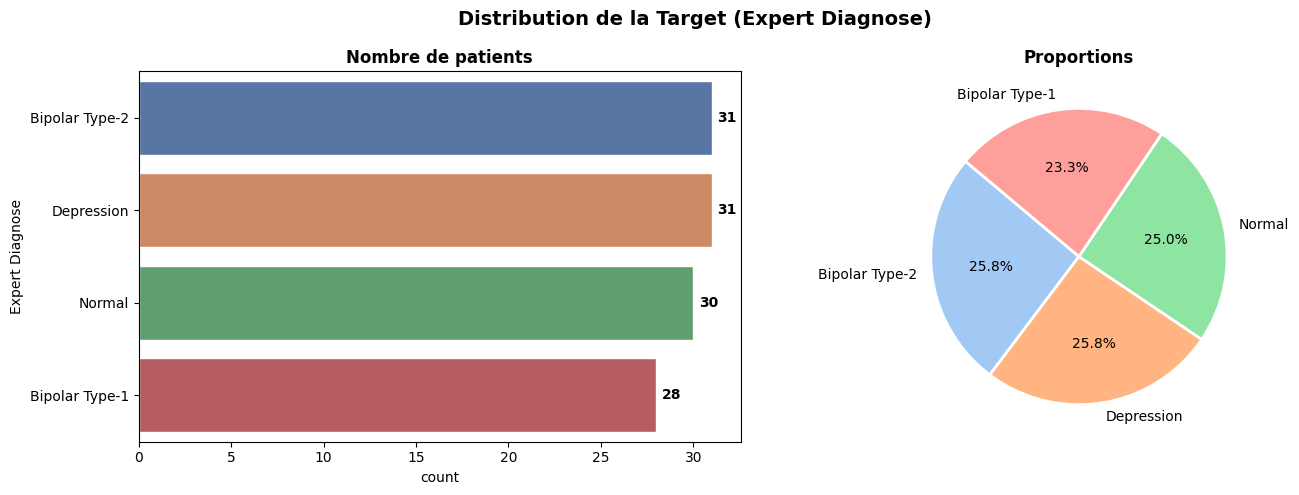

In [ ]:
PALETTE  = sns.color_palette('deep')
palettes = sns.color_palette('pastel')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Distribution de la Target (Expert Diagnose)", fontsize=14, fontweight='bold')

order = df['Expert Diagnose'].value_counts().index
sns.countplot(data=df, y='Expert Diagnose', order=order, palette=PALETTE, ax=axes[0], edgecolor='white')
for container in axes[0].containers:
    axes[0].bar_label(container, padding=4, fontweight='bold')
axes[0].set_title("Nombre de patients", fontweight='bold')

counts = df['Expert Diagnose'].value_counts()
axes[1].pie(counts.values, labels=counts.index, colors=palettes,
            autopct='%1.1f%%', startangle=140,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title("Proportions", fontweight='bold')

plt.tight_layout()
plt.savefig('A1_Target_Distribution.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

## 1.5 Visualisation — Variables binaires YES/NO par classe

In [ ]:
# Correction anomalie : espace trailing dans 'YES '
df['Suicidal thoughts'] = df['Suicidal thoughts'].replace('YES ', 'YES')
print("✓ Correction 'YES ' → 'YES'")
print(f"Doublons : {df.duplicated().sum()}")

✓ Correction 'YES ' → 'YES'
Doublons : 0


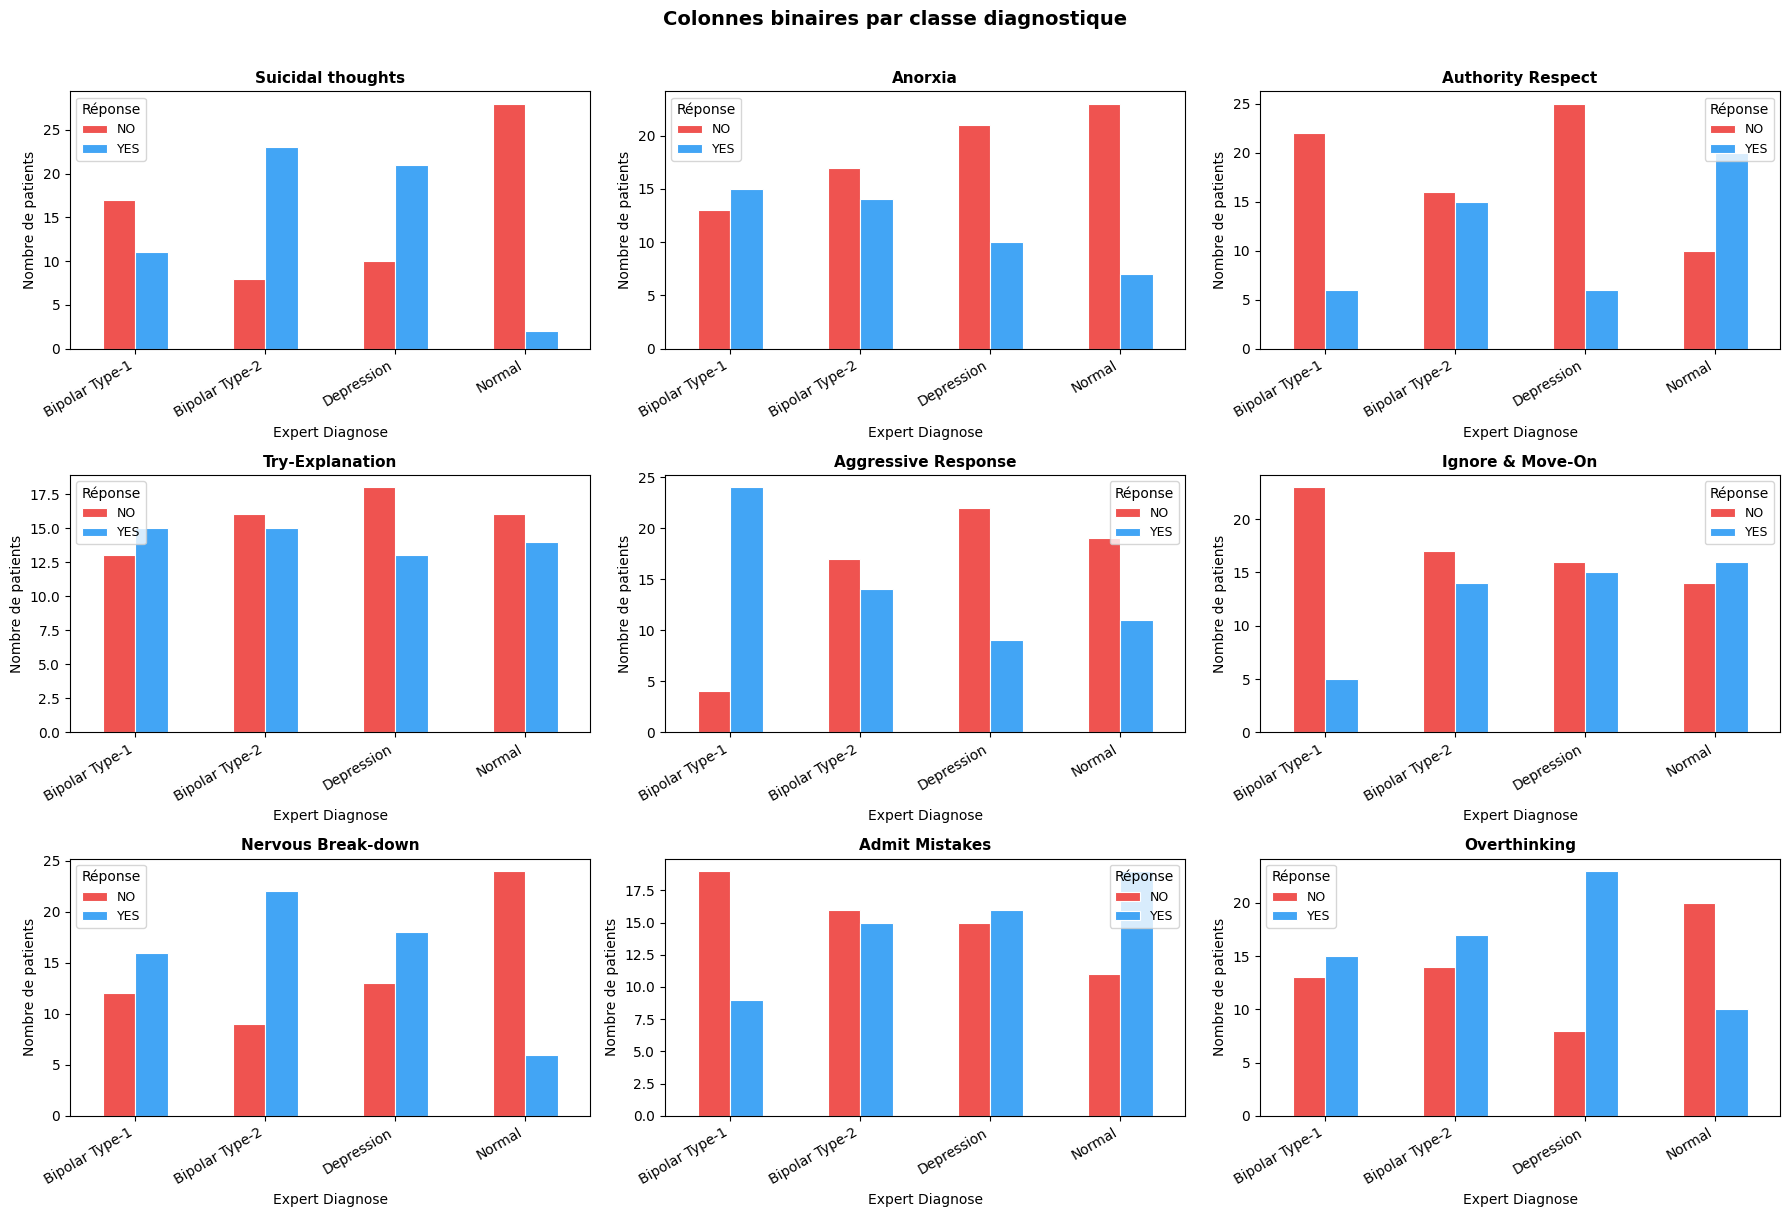

In [ ]:
binary_cols = ['Suicidal thoughts', 'Anorxia', 'Authority Respect',
               'Try-Explanation', 'Aggressive Response', 'Ignore & Move-On',
               'Nervous Break-down', 'Admit Mistakes', 'Overthinking']
binary_cols = [c for c in binary_cols if c in df.columns]

n_cols = 3
n_rows = int(np.ceil(len(binary_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
fig.suptitle("Colonnes binaires par classe diagnostique", fontsize=14, fontweight='bold', y=1.01)
axes = axes.flatten()

for i, col in enumerate(binary_cols):
    ct = pd.crosstab(df['Expert Diagnose'], df[col])
    ct.plot(kind='bar', ax=axes[i], color=['#EF5350', '#42A5F5'], edgecolor='white', linewidth=0.8)
    axes[i].set_title(col, fontweight='bold', fontsize=11)
    axes[i].set_ylabel("Nombre de patients")
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=30, ha='right')
    axes[i].legend(title='Réponse', fontsize=9)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig('A2_Binary_Raw.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

## 1.6 Visualisation — Variables ordinales

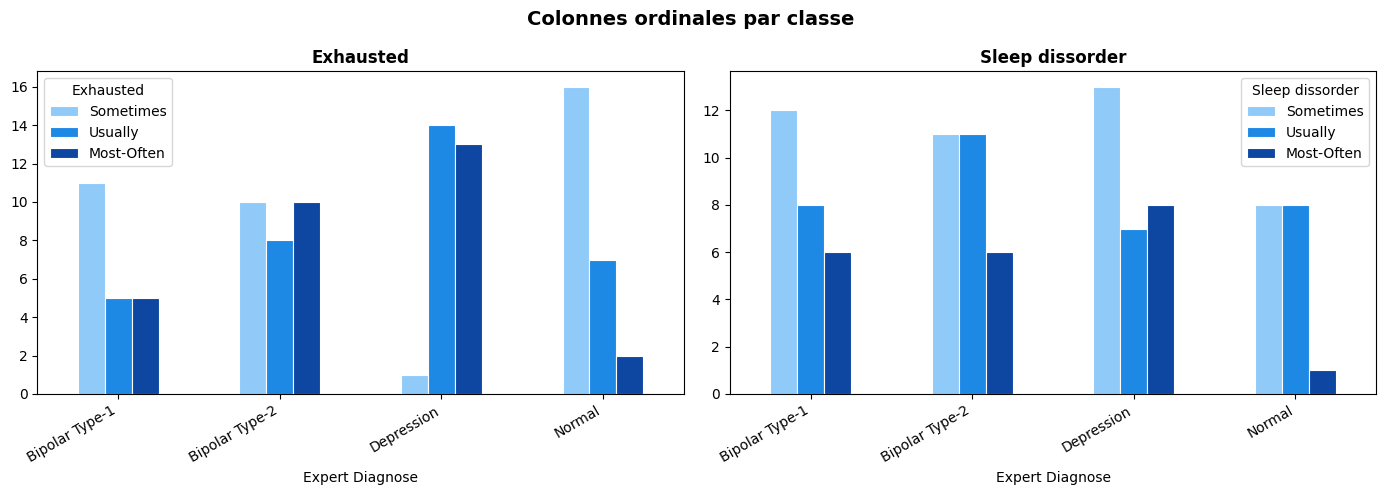

In [ ]:
ordinal_cols_viz = [c for c in ['Exhausted', 'Sleep dissorder'] if c in df.columns]
ordinal_order    = ['Sometimes', 'Usually', 'Most-Often']

fig, axes = plt.subplots(1, len(ordinal_cols_viz), figsize=(14, 5))
fig.suptitle("Colonnes ordinales par classe", fontsize=14, fontweight='bold')

for i, col in enumerate(ordinal_cols_viz):
    ct = pd.crosstab(df['Expert Diagnose'], df[col])
    existing_order = [v for v in ordinal_order if v in ct.columns]
    ct[existing_order].plot(kind='bar', ax=axes[i],
                            color=['#90CAF9', '#1E88E5', '#0D47A1'],
                            edgecolor='white', linewidth=0.8)
    axes[i].set_title(col, fontweight='bold')
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=30, ha='right')

plt.tight_layout()
plt.savefig('Ordinal_Raw.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

# 1.7 Prétraitement 

# Étape 1 : Binaires YES/NO → 0/1

In [ ]:
yes_no_cols = ['Mood Swing', 'Suicidal thoughts', 'Anorxia', 'Authority Respect',
               'Try-Explanation', 'Aggressive Response', 'Ignore & Move-On',
               'Nervous Break-down', 'Admit Mistakes', 'Overthinking']
for col in yes_no_cols:
    df[col] = df[col].map({'YES': 1, 'NO': 0}).astype(int)
print("✓ Binaires encodées")

✓ Binaires encodées


# Étape 2 : Ordinales → 1-4

In [ ]:
ordinal_map  = {'Seldom': 1, 'Sometimes': 2, 'Usually': 3, 'Most-Often': 4}
ordinal_cols = [c for c in ['Sadness', 'Euphoric', 'Exhausted', 'Sleep dissorder'] if c in df.columns]
for col in ordinal_cols:
    df[col] = df[col].str.strip().map(ordinal_map)
print("✓ Ordinales encodées")

✓ Ordinales encodées


# Étape 3 : Scores → entier 1-10

In [ ]:
def extract_score(val):
    try:    return int(str(val).strip().split()[0])
    except: return np.nan

score_cols = [c for c in ['Sexual Activity', 'Concentration', 'Optimisim'] if c in df.columns]
for col in score_cols:
    df[col] = df[col].apply(extract_score)
print("✓ Scores extraits")

✓ Scores extraits


# Étape 4 : Target


In [ ]:
df['Expert Diagnose'] = df['Expert Diagnose'].map({
    'Normal': 0, 'Bipolar Type-1': 1, 'Bipolar Type-2': 2, 'Depression': 3
}).astype(int)
print("✓ Target encodée")

✓ Target encodée


# Étape 5 : Suppression Patient Number


In [ ]:
df = df.drop('Patient Number', axis=1)
print(f"✓ Shape finale : {df.shape}")
df.head()

✓ Shape finale : (120, 18)


,Sadness,Euphoric,Exhausted,Sleep dissorder,Mood Swing,Suicidal thoughts,Anorxia,Authority Respect,Try-Explanation,Aggressive Response,Ignore & Move-On,Nervous Break-down,Admit Mistakes,Overthinking,Sexual Activity,Concentration,Optimisim,Expert Diagnose
0,3,1,2,2,1,1,0,0,1,0,0,1,1,1,3,3,4,2
1,3,1,3,2,0,1,0,0,0,0,0,0,0,0,4,2,5,3
2,2,4,2,2,1,0,0,0,1,1,0,1,1,0,6,5,7,1
3,3,1,3,4,1,1,1,0,1,0,0,0,0,0,3,2,2,2
4,3,3,2,2,0,0,0,0,0,0,0,1,1,1,5,5,6,0


In [ ]:
df

,Sadness,Euphoric,Exhausted,Sleep dissorder,Mood Swing,Suicidal thoughts,Anorxia,Authority Respect,Try-Explanation,Aggressive Response,Ignore & Move-On,Nervous Break-down,Admit Mistakes,Overthinking,Sexual Activity,Concentration,Optimisim,Expert Diagnose
0,3,1,2,2,1,1,0,0,1,0,0,1,1,1,3,3,4,2
1,3,1,3,2,0,1,0,0,0,0,0,0,0,0,4,2,5,3
2,2,4,2,2,1,0,0,0,1,1,0,1,1,0,6,5,7,1
3,3,1,3,4,1,1,1,0,1,0,0,0,0,0,3,2,2,2
4,3,3,2,2,0,0,0,0,0,0,0,1,1,1,5,5,6,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,4,1,3,2,0,1,0,0,1,0,1,0,0,1,2,5,3,3
116,2,2,2,1,1,0,0,0,0,1,0,0,0,1,6,7,8,1
117,3,2,3,2,1,0,1,1,0,0,0,1,0,1,1,5,3,2
118,3,2,1,1,0,1,1,0,1,1,1,0,1,1,7,7,7,3


## 1.8 Matrice de corrélation

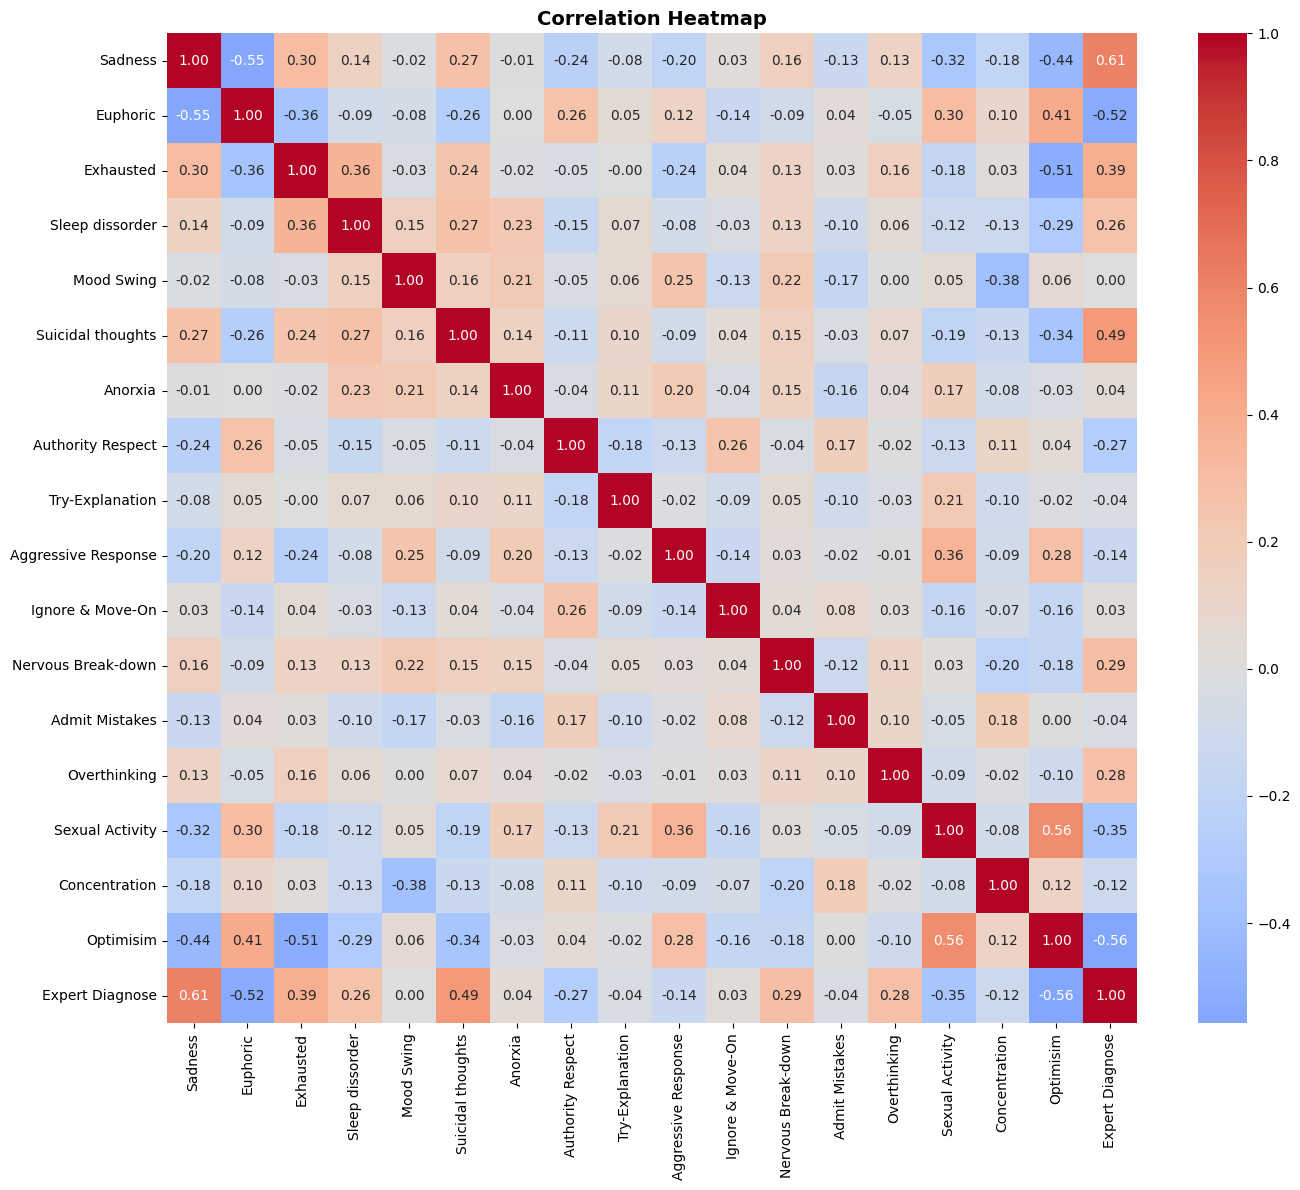

In [ ]:
plt.figure(figsize=(14, 12))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap='coolwarm', center=0)
plt.title('Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('Correlation_Heatmap.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

---
# PARTIE 2 — Modeles ML

## 2.1 Split 60 / 20 / 20 Stratifié 


In [ ]:
X = df.drop(columns=['Expert Diagnose'])
y = df['Expert Diagnose']
class_names = ['Normal', 'Bipolar Type-1', 'Bipolar Type-2', 'Depression']

# ── Étape 1 : Séparer 60% train / 40% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=42, stratify=y
)

# ── Étape 2 : Diviser le temp en 50% val / 50% test
# → 20% val + 20% test sur les données totales
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Train      : {X_train.shape[0]} patients  | Distribution : {dict(y_train.value_counts().sort_index())}")
print(f"Validation : {X_val.shape[0]} patients  | Distribution : {dict(y_val.value_counts().sort_index())}")
print(f"Test       : {X_test.shape[0]} patients  | Distribution : {dict(y_test.value_counts().sort_index())}")
print(f"\n✓ Test set gelé — ne sera utilisé qu'en évaluation finale")

Train      : 72 patients  | Distribution : {0: np.int64(18), 1: np.int64(17), 2: np.int64(18), 3: np.int64(19)}
Validation : 24 patients  | Distribution : {0: np.int64(6), 1: np.int64(5), 2: np.int64(7), 3: np.int64(6)}
Test       : 24 patients  | Distribution : {0: np.int64(6), 1: np.int64(6), 2: np.int64(6), 3: np.int64(6)}

✓ Test set gelé — ne sera utilisé qu'en évaluation finale


## 2.2 Cross-Validation StratifiedKFold (k=5) — 5 modèles

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression" : LogisticRegression(max_iter=1000),
    "Random Forest"       : RandomForestClassifier(n_estimators=200, random_state=42),
    "SVM"                 : SVC(kernel='rbf', probability=True, random_state=42),
    "KNN"                 : KNeighborsClassifier(n_neighbors=5),
    "Decision Tree"       : DecisionTreeClassifier(random_state=42)
}

results = []
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=skf, scoring='accuracy')
    results.append({'Modèle': name,
                    'Accuracy Moyenne': scores.mean(),
                    'Écart-type'      : scores.std()})
    print(f"{name} — Moyenne : {scores.mean():.4f} | Std : {scores.std():.4f}")

results_df = pd.DataFrame(results).sort_values('Accuracy Moyenne', ascending=False)
print(f"\n→ Meilleur modèle : {results_df.iloc[0]['Modèle']}")

Logistic Regression — Moyenne : 0.8076 | Std : 0.0607
Random Forest — Moyenne : 0.8467 | Std : 0.0825
SVM — Moyenne : 0.6543 | Std : 0.1220
KNN — Moyenne : 0.6514 | Std : 0.1042
Decision Tree — Moyenne : 0.7219 | Std : 0.0625

→ Meilleur modèle : Random Forest


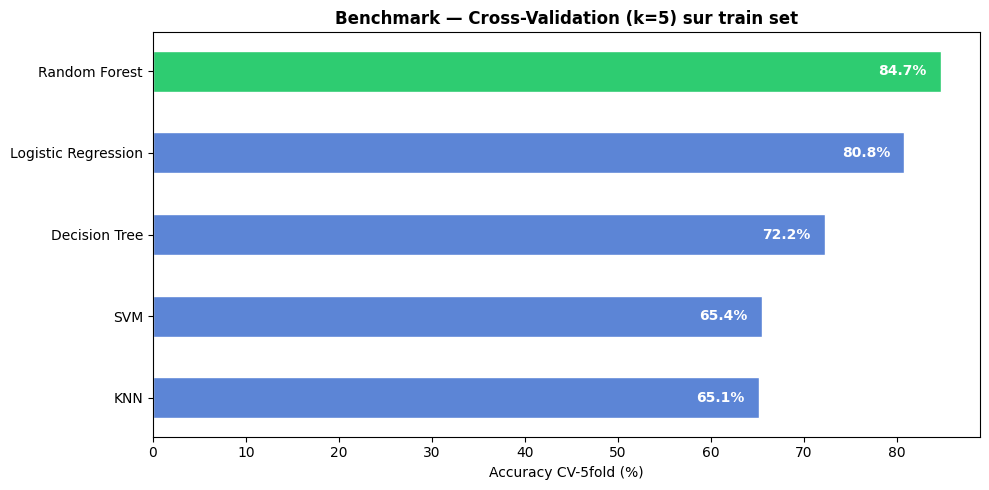

In [ ]:
# Visualisation benchmark
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#2ECC71' if i == 0 else '#5C85D6' for i in range(len(results_df))]
bars = ax.barh(results_df['Modèle'], results_df['Accuracy Moyenne'] * 100,
               color=colors, edgecolor='white', height=0.5)
for bar, val in zip(bars, results_df['Accuracy Moyenne'] * 100):
    ax.text(bar.get_width() - 1.5, bar.get_y() + bar.get_height() / 2,
            f'{val:.1f}%', va='center', ha='right', fontweight='bold', color='white')
ax.set_xlabel('Accuracy CV-5fold (%)')
ax.set_title('Benchmark — Cross-Validation (k=5) sur train set', fontweight='bold')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('Benchmark_CV.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

## 2.3 Random Forest — Entraînement et Évaluation finale

In [ ]:
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf  = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)
acc_rf     = accuracy_score(y_test, y_pred_rf)

print("=" * 55)
print("PERFORMANCE — RANDOM FOREST (test set vierge)")
print("=" * 55)
print(f"Accuracy  : {acc_rf:.4f}")
print(f"Precision : {precision_score(y_test, y_pred_rf, average='weighted'):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_rf, average='weighted'):.4f}")
print(f"F1-score  : {f1_score(y_test, y_pred_rf, average='weighted'):.4f}")
print()
print(classification_report(y_test, y_pred_rf, target_names=class_names))

PERFORMANCE — RANDOM FOREST (test set vierge)
Accuracy  : 0.8750
Precision : 0.9018
Recall    : 0.8750
F1-score  : 0.8617

                precision    recall  f1-score   support

        Normal       0.86      1.00      0.92         6
Bipolar Type-1       1.00      0.50      0.67         6
Bipolar Type-2       0.75      1.00      0.86         6
    Depression       1.00      1.00      1.00         6

      accuracy                           0.88        24
     macro avg       0.90      0.88      0.86        24
  weighted avg       0.90      0.88      0.86        24



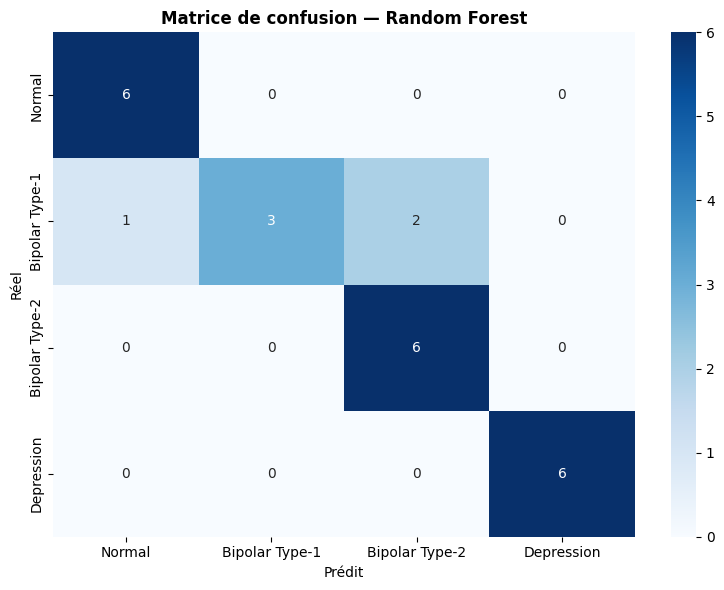

In [ ]:
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.title("Matrice de confusion — Random Forest", fontweight='bold')
plt.tight_layout()
plt.savefig('CM_RF.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

## 2.4 Feature Importance — Random Forest

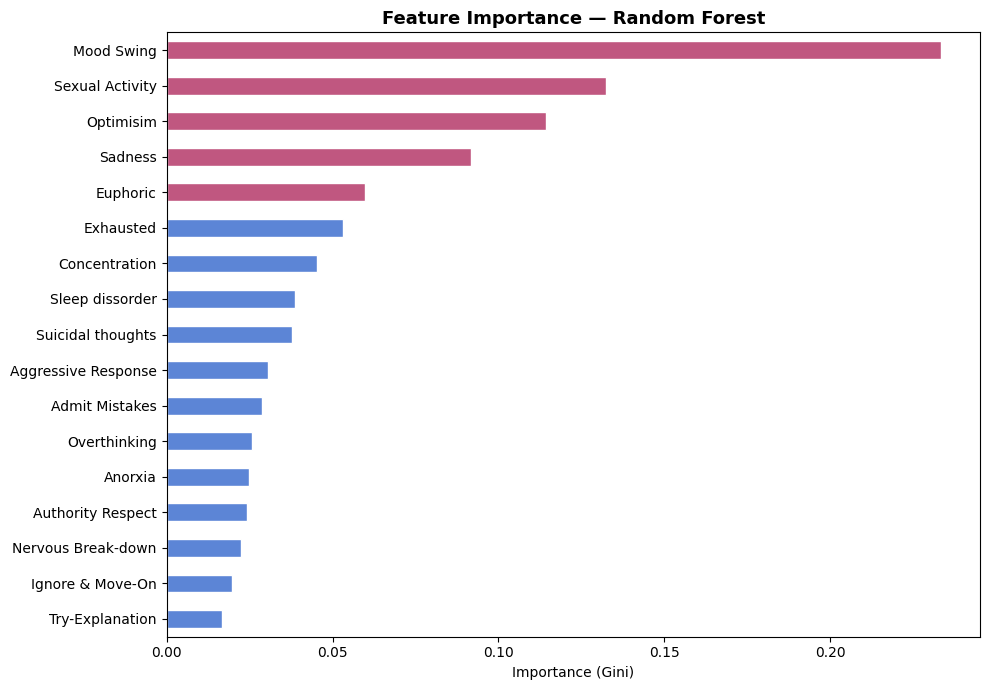

In [ ]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=True)

plt.figure(figsize=(10, 7))
colors = ['#C05780' if v >= importances.quantile(0.75) else '#5C85D6' for v in importances]
importances.plot(kind='barh', color=colors, edgecolor='white')
plt.xlabel('Importance (Gini)')
plt.title('Feature Importance — Random Forest', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('Feature_Importance.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

---
# PARTIE 3 — AUGMENTATION + RÉSEAUX DE NEURONES

## 3.1 Augmentation SMOTE + bruit conservateur

In [ ]:
def add_smart_noise(X_df, noise_level=0.05, seed=42):
    """
    Bruit conservateur (5%) respectant les contraintes médicales.
    Ordinales [1-4], binaires [0-1], scores [1-10].
    """
    rng   = np.random.default_rng(seed)
    X_out = X_df.copy()

    ordinal_features = [c for c in ['Sadness', 'Euphoric', 'Exhausted', 'Sleep dissorder']
                        if c in X_out.columns]
    for col in ordinal_features:
        mask  = rng.random(len(X_out)) < noise_level
        delta = rng.choice([-1, 1], size=mask.sum())
        X_out.loc[mask, col] = (X_out.loc[mask, col] + delta).clip(1, 4)

    binary_features = [c for c in ['Mood Swing', 'Suicidal thoughts', 'Anorxia',
                                   'Authority Respect', 'Try-Explanation', 'Aggressive Response',
                                   'Ignore & Move-On', 'Nervous Break-down', 'Admit Mistakes',
                                   'Overthinking'] if c in X_out.columns]
    for col in binary_features:
        mask = rng.random(len(X_out)) < noise_level * 0.6
        X_out.loc[mask, col] = 1 - X_out.loc[mask, col]

    score_features = [c for c in ['Sexual Activity', 'Concentration', 'Optimisim']
                      if c in X_out.columns]
    for col in score_features:
        mask  = rng.random(len(X_out)) < noise_level
        delta = rng.choice([-1, 1], size=mask.sum())
        X_out.loc[mask, col] = (X_out.loc[mask, col] + delta).clip(1, 10)

    return X_out

print("✓ Fonction de bruit définie")

In [ ]:
print("=" * 60)
print("AUGMENTATION SMOTE — ÉQUILIBRAGE MODÉRÉ")
print("=" * 60)
print()

# ── Analyse de la distribution réelle du train set ──────────────
class_counts = dict(y_train.value_counts().sort_index())
max_class    = max(class_counts.values())

print("Distribution initiale du train set :")
for cls, cnt in class_counts.items():
    print(f"  Classe {cls} : {cnt} patients")
print()

n_target     = max_class + 5         
n_target     = max(n_target, 35)     

# Construction de la stratégie : seulement les classes sous la cible
sampling_strategy = {
    cls: n_target
    for cls, cnt in class_counts.items()
    if cnt < n_target
}

print(f"Cible par classe  : {n_target} exemples")
print(f"Classes à rééchantillonner : {list(sampling_strategy.keys())}")
print()

# ── SMOTE uniquement sur train ────────────────────────────────────
print("[1/1] Application de SMOTE...")
smote = SMOTE(sampling_strategy=sampling_strategy, k_neighbors=3, random_state=42)
X_train_aug_np, y_train_aug = smote.fit_resample(X_train, y_train)
X_train_aug = pd.DataFrame(X_train_aug_np, columns=X_train.columns)

# ── Mélange aléatoire ────────────────────────────────────────────
idx         = np.random.default_rng(42).permutation(len(X_train_aug))
X_train_aug = X_train_aug.iloc[idx].reset_index(drop=True)
y_train_aug = y_train_aug[idx]

n_artificial = X_train_aug.shape[0] - X_train.shape[0]

print()
print(f"✓ Train original   : {X_train.shape[0]} patients réels")
print(f"✓ Lignes ajoutées  : {n_artificial} lignes SMOTE")
print(f"✓ Train augmenté   : {X_train_aug.shape[0]} lignes × {X_train_aug.shape[1]} features")
print(f"  Rapport          : ×{X_train_aug.shape[0] / X_train.shape[0]:.2f} vs train original")
print(f"  Distribution     : {dict(zip(*np.unique(y_train_aug, return_counts=True)))}")
print()
print("✓ Val set  (24 patients) intact — utilisé pour early stopping")
print("✓ Test set (24 patients) intact — jamais touché")


## 3.2 Normalisation

In [ ]:
# Scaler fit UNIQUEMENT sur train augmenté
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_aug)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)

n_classes   = 4
n_features  = X_train_scaled.shape[1]
y_train_cat = to_categorical(y_train_aug, num_classes=n_classes)
y_val_cat   = to_categorical(y_val,       num_classes=n_classes)
y_test_cat  = to_categorical(y_test,      num_classes=n_classes)

print(f"✓ X_train_scaled : {X_train_scaled.shape}")
print(f"✓ X_val_scaled   : {X_val_scaled.shape}  ← early stopping")
print(f"✓ X_test_scaled  : {X_test_scaled.shape}  ← évaluation finale uniquement")

## 3.3 Réseau Neuronal Simple


In [ ]:
model_simple = Sequential([
    Dense(64, activation='relu', input_shape=(n_features,)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(4, activation='softmax')
], name="reseau_simple")

model_simple.compile(
    optimizer = Adam(learning_rate=0.001),
    loss      = 'categorical_crossentropy',
    metrics   = ['accuracy']
)

model_simple.summary()

# Early stopping sur le VAL SET (indépendant du test)
early_stop_simple = EarlyStopping(
    monitor              = 'val_loss',
    patience             = 20,
    restore_best_weights = True,
    verbose              = 1
)

reduce_lr_simple = ReduceLROnPlateau(
    monitor   = 'val_loss',
    factor    = 0.5,
    patience  = 8,
    min_lr    = 1e-6,
    verbose   = 1
)

print(f"Train   : {len(X_train_aug)} lignes augmentées")
print(f"Val     : {len(X_val)} vrais patients (early stopping)")
print(f"Epochs  : 150 max (early stopping patience=20)\n")

history_simple = model_simple.fit(
    X_train_scaled, y_train_cat,
    epochs          = 150,
    batch_size      = 32,
    validation_data = (X_val_scaled, y_val_cat),
    callbacks       = [early_stop_simple, reduce_lr_simple],
    verbose         = 1
)

In [ ]:
loss_simple, acc_simple = model_simple.evaluate(X_test_scaled, y_test_cat, verbose=0)
y_pred_simple           = np.argmax(model_simple.predict(X_test_scaled), axis=1)

print("=" * 55)
print("PERFORMANCE — RÉSEAU SIMPLE (test set vierge)")
print("=" * 55)
print(f"Accuracy : {acc_simple:.4f}")
print(f"Loss     : {loss_simple:.4f}")
print()
print(classification_report(y_test, y_pred_simple, target_names=class_names))

cm_simple = confusion_matrix(y_test, y_pred_simple)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_simple, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.title("Matrice de confusion — Réseau Simple", fontweight='bold')
plt.tight_layout()
plt.savefig('CM_NN_Simple.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

## 3.4 Réseau Neuronal Amélioré


In [ ]:
model_improved = Sequential([
    # Couche 1 — extraction des patterns principaux
    Dense(64, activation='relu', input_shape=(n_features,)),
    BatchNormalization(),
    Dropout(0.4),

    # Couche 2 — représentation intermédiaire
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    # Sortie
    Dense(4, activation='softmax')
], name="reseau_ameliore")

model_improved.compile(
    optimizer = Adam(learning_rate=0.001),
    loss      = 'categorical_crossentropy',
    metrics   = ['accuracy']
)

model_improved.summary()

early_stop_improved = EarlyStopping(
    monitor              = 'val_loss',
    patience             = 20,
    restore_best_weights = True,
    verbose              = 1
)

reduce_lr_improved = ReduceLROnPlateau(
    monitor   = 'val_loss',
    factor    = 0.5,
    patience  = 8,
    min_lr    = 1e-6,
    verbose   = 1
)

print(f"Train   : {len(X_train_aug)} lignes augmentées")
print(f"Val     : {len(X_val)} vrais patients (early stopping)")
print(f"Epochs  : 150 max (early stopping patience=20)\n")

history_improved = model_improved.fit(
    X_train_scaled, y_train_cat,
    epochs          = 150,
    batch_size      = 16,
    validation_data = (X_val_scaled, y_val_cat),
    callbacks       = [early_stop_improved, reduce_lr_improved],
    verbose         = 1
)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
PERFORMANCE — RÉSEAU AMÉLIORÉ (test set vierge)
Accuracy : 0.8333
Loss     : 0.5927

                precision    recall  f1-score   support

        Normal       0.83      0.83      0.83         6
Bipolar Type-1       0.75      0.50      0.60         6
Bipolar Type-2       0.75      1.00      0.86         6
    Depression       1.00      1.00      1.00         6

      accuracy                           0.83        24
     macro avg       0.83      0.83      0.82        24
  weighted avg       0.83      0.83      0.82        24



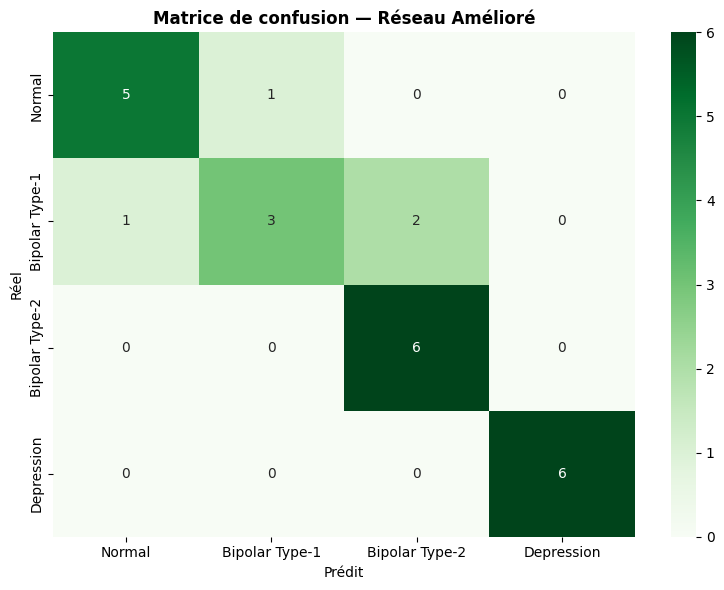

In [ ]:
loss_improved, acc_improved = model_improved.evaluate(X_test_scaled, y_test_cat, verbose=0)
y_pred_improved             = np.argmax(model_improved.predict(X_test_scaled), axis=1)

print("=" * 55)
print("PERFORMANCE — RÉSEAU AMÉLIORÉ (test set vierge)")
print("=" * 55)
print(f"Accuracy : {acc_improved:.4f}")
print(f"Loss     : {loss_improved:.4f}")
print()
print(classification_report(y_test, y_pred_improved, target_names=class_names))

cm_improved = confusion_matrix(y_test, y_pred_improved)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_improved, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.title("Matrice de confusion — Réseau Amélioré", fontweight='bold')
plt.tight_layout()
plt.savefig('CM_NN_Ameliore.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

## 3.5 Courbes d'Apprentissage

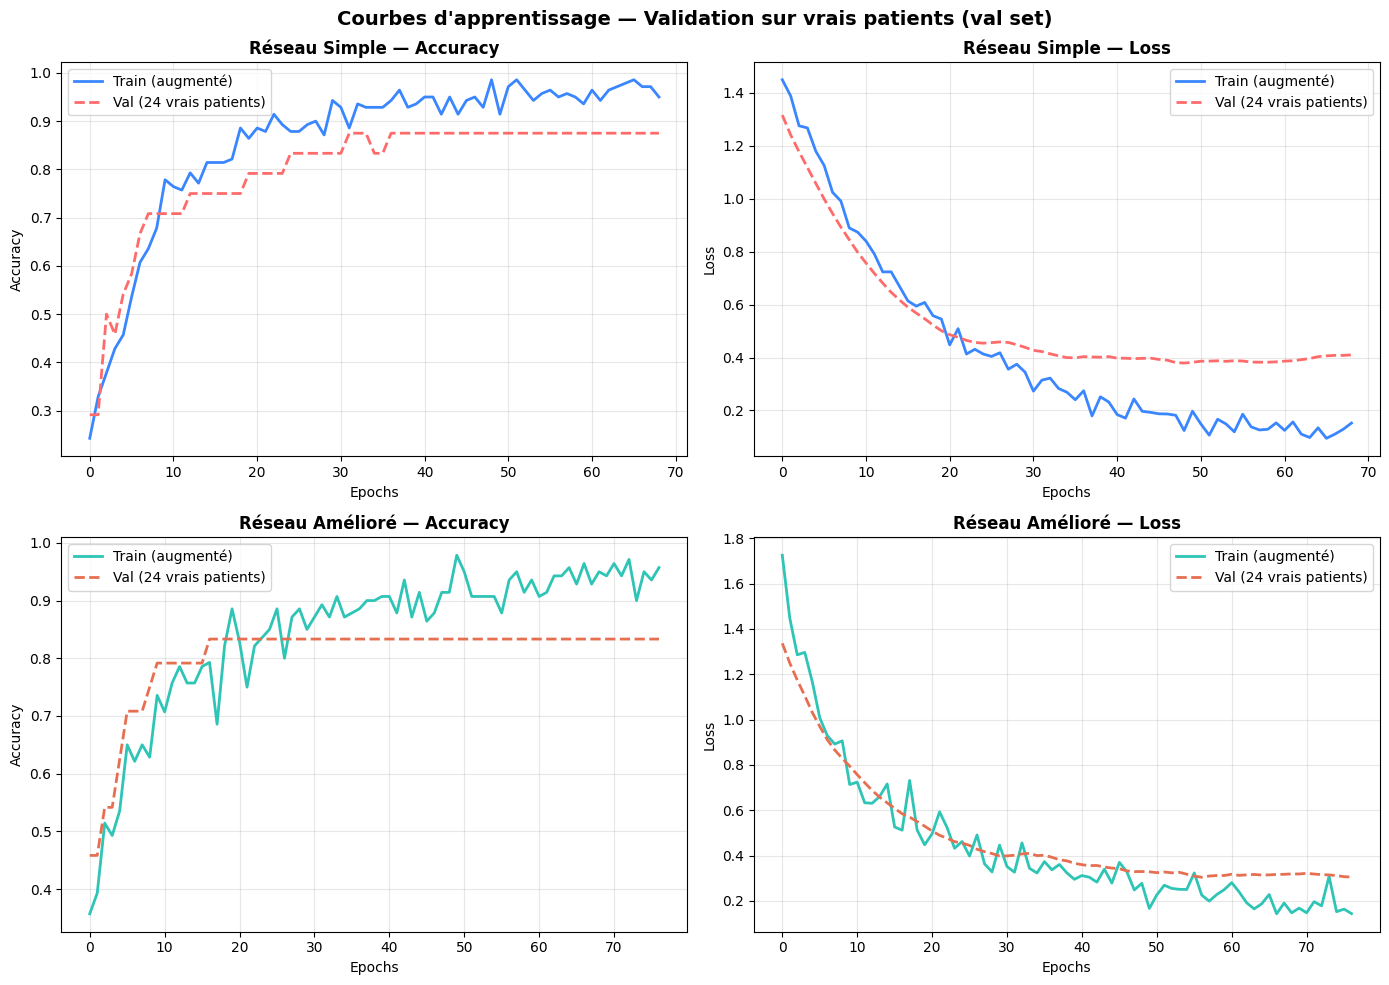

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Courbes d'apprentissage — Validation sur vrais patients (val set)",
             fontsize=14, fontweight='bold')

# Réseau Simple
axes[0, 0].plot(history_simple.history['accuracy'],
                label='Train (augmenté)', color='#3A86FF', linewidth=2)
axes[0, 0].plot(history_simple.history['val_accuracy'],
                label='Val (24 vrais patients)', color='#FF6B6B', linewidth=2, linestyle='--')
axes[0, 0].set_title('Réseau Simple — Accuracy', fontweight='bold')
axes[0, 0].set_xlabel('Epochs')
axes[0, 0].set_ylabel('Accuracy')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(history_simple.history['loss'],
                label='Train (augmenté)', color='#3A86FF', linewidth=2)
axes[0, 1].plot(history_simple.history['val_loss'],
                label='Val (24 vrais patients)', color='#FF6B6B', linewidth=2, linestyle='--')
axes[0, 1].set_title('Réseau Simple — Loss', fontweight='bold')
axes[0, 1].set_xlabel('Epochs')
axes[0, 1].set_ylabel('Loss')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Réseau Amélioré
axes[1, 0].plot(history_improved.history['accuracy'],
                label='Train (augmenté)', color='#2EC4B6', linewidth=2)
axes[1, 0].plot(history_improved.history['val_accuracy'],
                label='Val (24 vrais patients)', color='#E76F51', linewidth=2, linestyle='--')
axes[1, 0].set_title('Réseau Amélioré — Accuracy', fontweight='bold')
axes[1, 0].set_xlabel('Epochs')
axes[1, 0].set_ylabel('Accuracy')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(history_improved.history['loss'],
                label='Train (augmenté)', color='#2EC4B6', linewidth=2)
axes[1, 1].plot(history_improved.history['val_loss'],
                label='Val (24 vrais patients)', color='#E76F51', linewidth=2, linestyle='--')
axes[1, 1].set_title('Réseau Amélioré — Loss', fontweight='bold')
axes[1, 1].set_xlabel('Epochs')
axes[1, 1].set_ylabel('Loss')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('Learning_Curves_v5.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

## 3.6 Tableau Comparatif Final

TABLEAU COMPARATIF FINAL — TOUS LES MODÈLES
         Modèle                      Train data            Validation  Accuracy Test (%)                                Anti-overfitting
  Random Forest                    72 originaux       CV-5fold sur 72              87.50                              Bagging 200 arbres
  Réseau Simple 140 augmentés (SMOTE équilibré) 24 patients (val set)              87.50             Dropout + Early Stopping (val réel)
Réseau Amélioré 140 augmentés (SMOTE équilibré) 24 patients (val set)              83.33 Dropout + BatchNorm + Early Stopping (val réel)


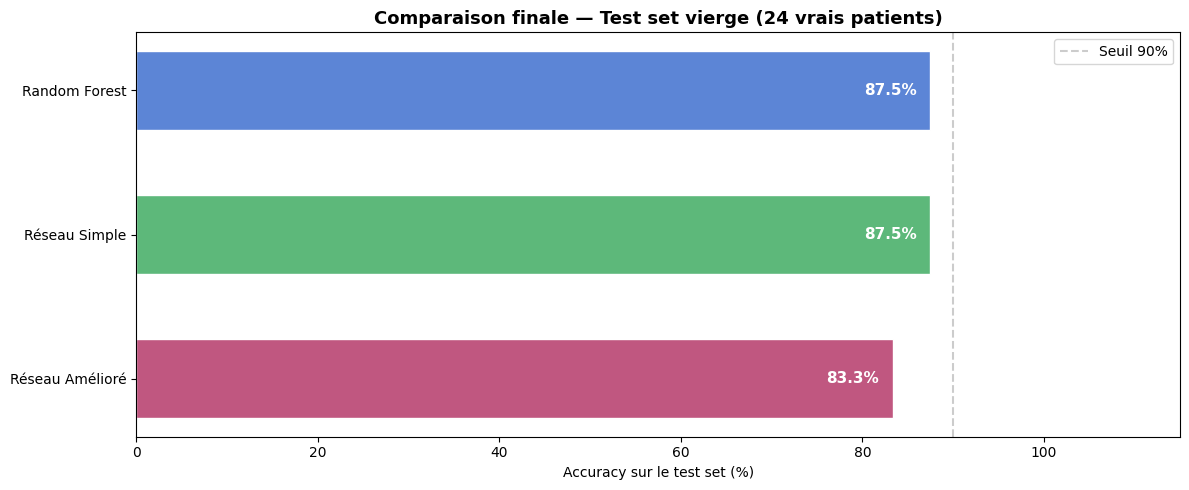

In [ ]:
print("=" * 75)
print("TABLEAU COMPARATIF FINAL — TOUS LES MODÈLES")
print("=" * 75)

comparison = pd.DataFrame({
    'Modèle': [
        'Random Forest',
        'Réseau Simple',
        'Réseau Amélioré'
    ],
    'Train data': [
        '72 originaux',
        f'{X_train_aug.shape[0]} augmentés (SMOTE équilibré)',
        f'{X_train_aug.shape[0]} augmentés (SMOTE équilibré)'
    ],
    'Validation': [
        'CV-5fold sur 72',
        '24 patients (val set)',
        '24 patients (val set)'
    ],
    'Accuracy Test (%)': [
        round(acc_rf       * 100, 2),
        round(acc_simple   * 100, 2),
        round(acc_improved * 100, 2)
    ],
    'Anti-overfitting': [
        'Bagging 200 arbres',
        'Dropout + Early Stopping (val réel)',
        'Dropout + BatchNorm + Early Stopping (val réel)'
    ]
})

print(comparison.sort_values('Accuracy Test (%)', ascending=False).to_string(index=False))

# Graphique
fig, ax = plt.subplots(figsize=(12, 5))
colors = ['#5C85D6', '#5DB87A', '#C05780']
bars = ax.barh(
    comparison['Modèle'],
    comparison['Accuracy Test (%)'],
    color=colors, edgecolor='white', height=0.55
)
for bar, val in zip(bars, comparison['Accuracy Test (%)']):
    ax.text(bar.get_width() - 1.5, bar.get_y() + bar.get_height() / 2,
            f'{val:.1f}%', va='center', ha='right',
            fontweight='bold', color='white', fontsize=11)

ax.set_xlabel('Accuracy sur le test set (%)')
ax.set_title('Comparaison finale — Test set vierge (24 vrais patients)',
             fontweight='bold', fontsize=13)
ax.set_xlim(0, 115)
ax.axvline(x=90, color='gray', linestyle='--', alpha=0.4, label='Seuil 90%')
ax.legend()
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('Model_Comparison_Final_v5.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()